# Explainable carbon intensity of national power systems (OWID, 2000–2025)

Notebook thực nghiệm chính thức cho luận văn. Mọi bảng/số trong paper được tạo từ lần chạy này. Siêu tham số được chọn bằng validation RMSE; test chỉ dùng để báo cáo; kịch bản mô hình không được diễn giải như quan hệ nhân quả.

Trước khi chạy, notebook cài các dependency từ `requirements.txt`, sau đó tải trực tiếp CSV từ OWID Grapher API; không cần tải hoặc đặt dataset raw thủ công.

## 1. Cài đặt và import thư viện

Ô code tiếp theo cài dependency từ `requirements.txt`, thiết lập đường dẫn dự án và import các thư viện/pipeline cần thiết.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

requirements = ROOT / "requirements.txt"
if not requirements.is_file():
    raise FileNotFoundError(f"Project requirements file not found: {requirements}")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-r", str(requirements)],
    check=True,
)

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(ROOT / "src"))
from thesis_workflow import run_thesis, TABLE_DIR, FIGURE_DIR

ROOT

WindowsPath('D:/OneDrive - University Of Industry and Trade/kmeans-owid-country-development/kmeans-owid-country-development')

## 2. Khai báo nguồn CSV chính thức từ OWID Grapher API

Các URL được lấy từ cấu hình nguồn dùng chung với pipeline để tránh khai báo trùng và lệch nguồn.

In [2]:
from carbon_intensity_workflow import SOURCE_URLS

print("Official OWID Grapher CSV sources:")
for source_name, source_url in SOURCE_URLS.items():
    print(f"- {source_name}: {source_url}")

Official OWID Grapher CSV sources:
- electricity_by_source: https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=by_source&frequency=annual
- electricity_generation: https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=generation&frequency=annual
- electricity_demand: https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=demand&frequency=annual
- net_imports: https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=net_imports&frequency=annual
- electricity_per_capita: https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=per_capita&frequency=annual
- population: https://ourworldindata.org/grapher/population.csv?v=1&csvType=full&useColumnShortNames=false
- gdp_per_capita: 

## 3. Chạy pipeline end-to-end
Tải trực tiếp CSV OWID Grapher API, tạo panel, audit missing/outlier/leakage/VIF, huấn luyện sáu họ mô hình, chạy ba giao thức đánh giá, XAI, phân tích dị biệt, Việt Nam và kịch bản.

In [3]:
import importlib
import thesis_workflow

importlib.reload(thesis_workflow)
summary = thesis_workflow.run_thesis(force_download=True)
summary

{'panel_rows': 5267,
 'countries': 210,
 'years': [2000, 2025],
 'best_model_selected_by_temporal_validation_rmse': 'catboost',
 'metrics_path': 'D:\\OneDrive - University Of Industry and Trade\\kmeans-owid-country-development\\kmeans-owid-country-development\\outputs\\thesis\\tables\\model_metrics.csv',
 'figures': 12}

## 4. Kiểm tra panel và chất lượng dữ liệu

,value
rows_before_sparse_rule,5387
rows_after_sparse_rule,5267
rows_excluded_sparse,120
countries,210
regions,5
year_min,2000
year_max,2025
target_outliers_iqr,25
target_outlier_lower,-285.2725
target_outlier_upper,1215.9475


,variable,missing_percent
15,gdp,10.100627
14,population,5.335105
7,renewables_share_elec,3.759256
4,wind_share_elec,2.449212
5,hydro_share_elec,1.404974
1,gas_share_elec,1.234099
6,nuclear_share_elec,0.835390
0,coal_share_elec,0.208848
9,other_renewables_share_elec,0.132903
8,biofuel_share_elec,0.000000


,feature,vif
0,log_electricity_demand,3.510695
1,log_population,2.600783
2,gas_share_elec,1.702220
3,coal_share_elec,1.616196
4,hydro_share_elec,1.546379
5,nuclear_share_elec,1.327919
6,year_centered,1.148796
7,wind_share_elec,1.145984
8,solar_share_elec,1.139151
9,net_elec_imports_share_demand,1.082188


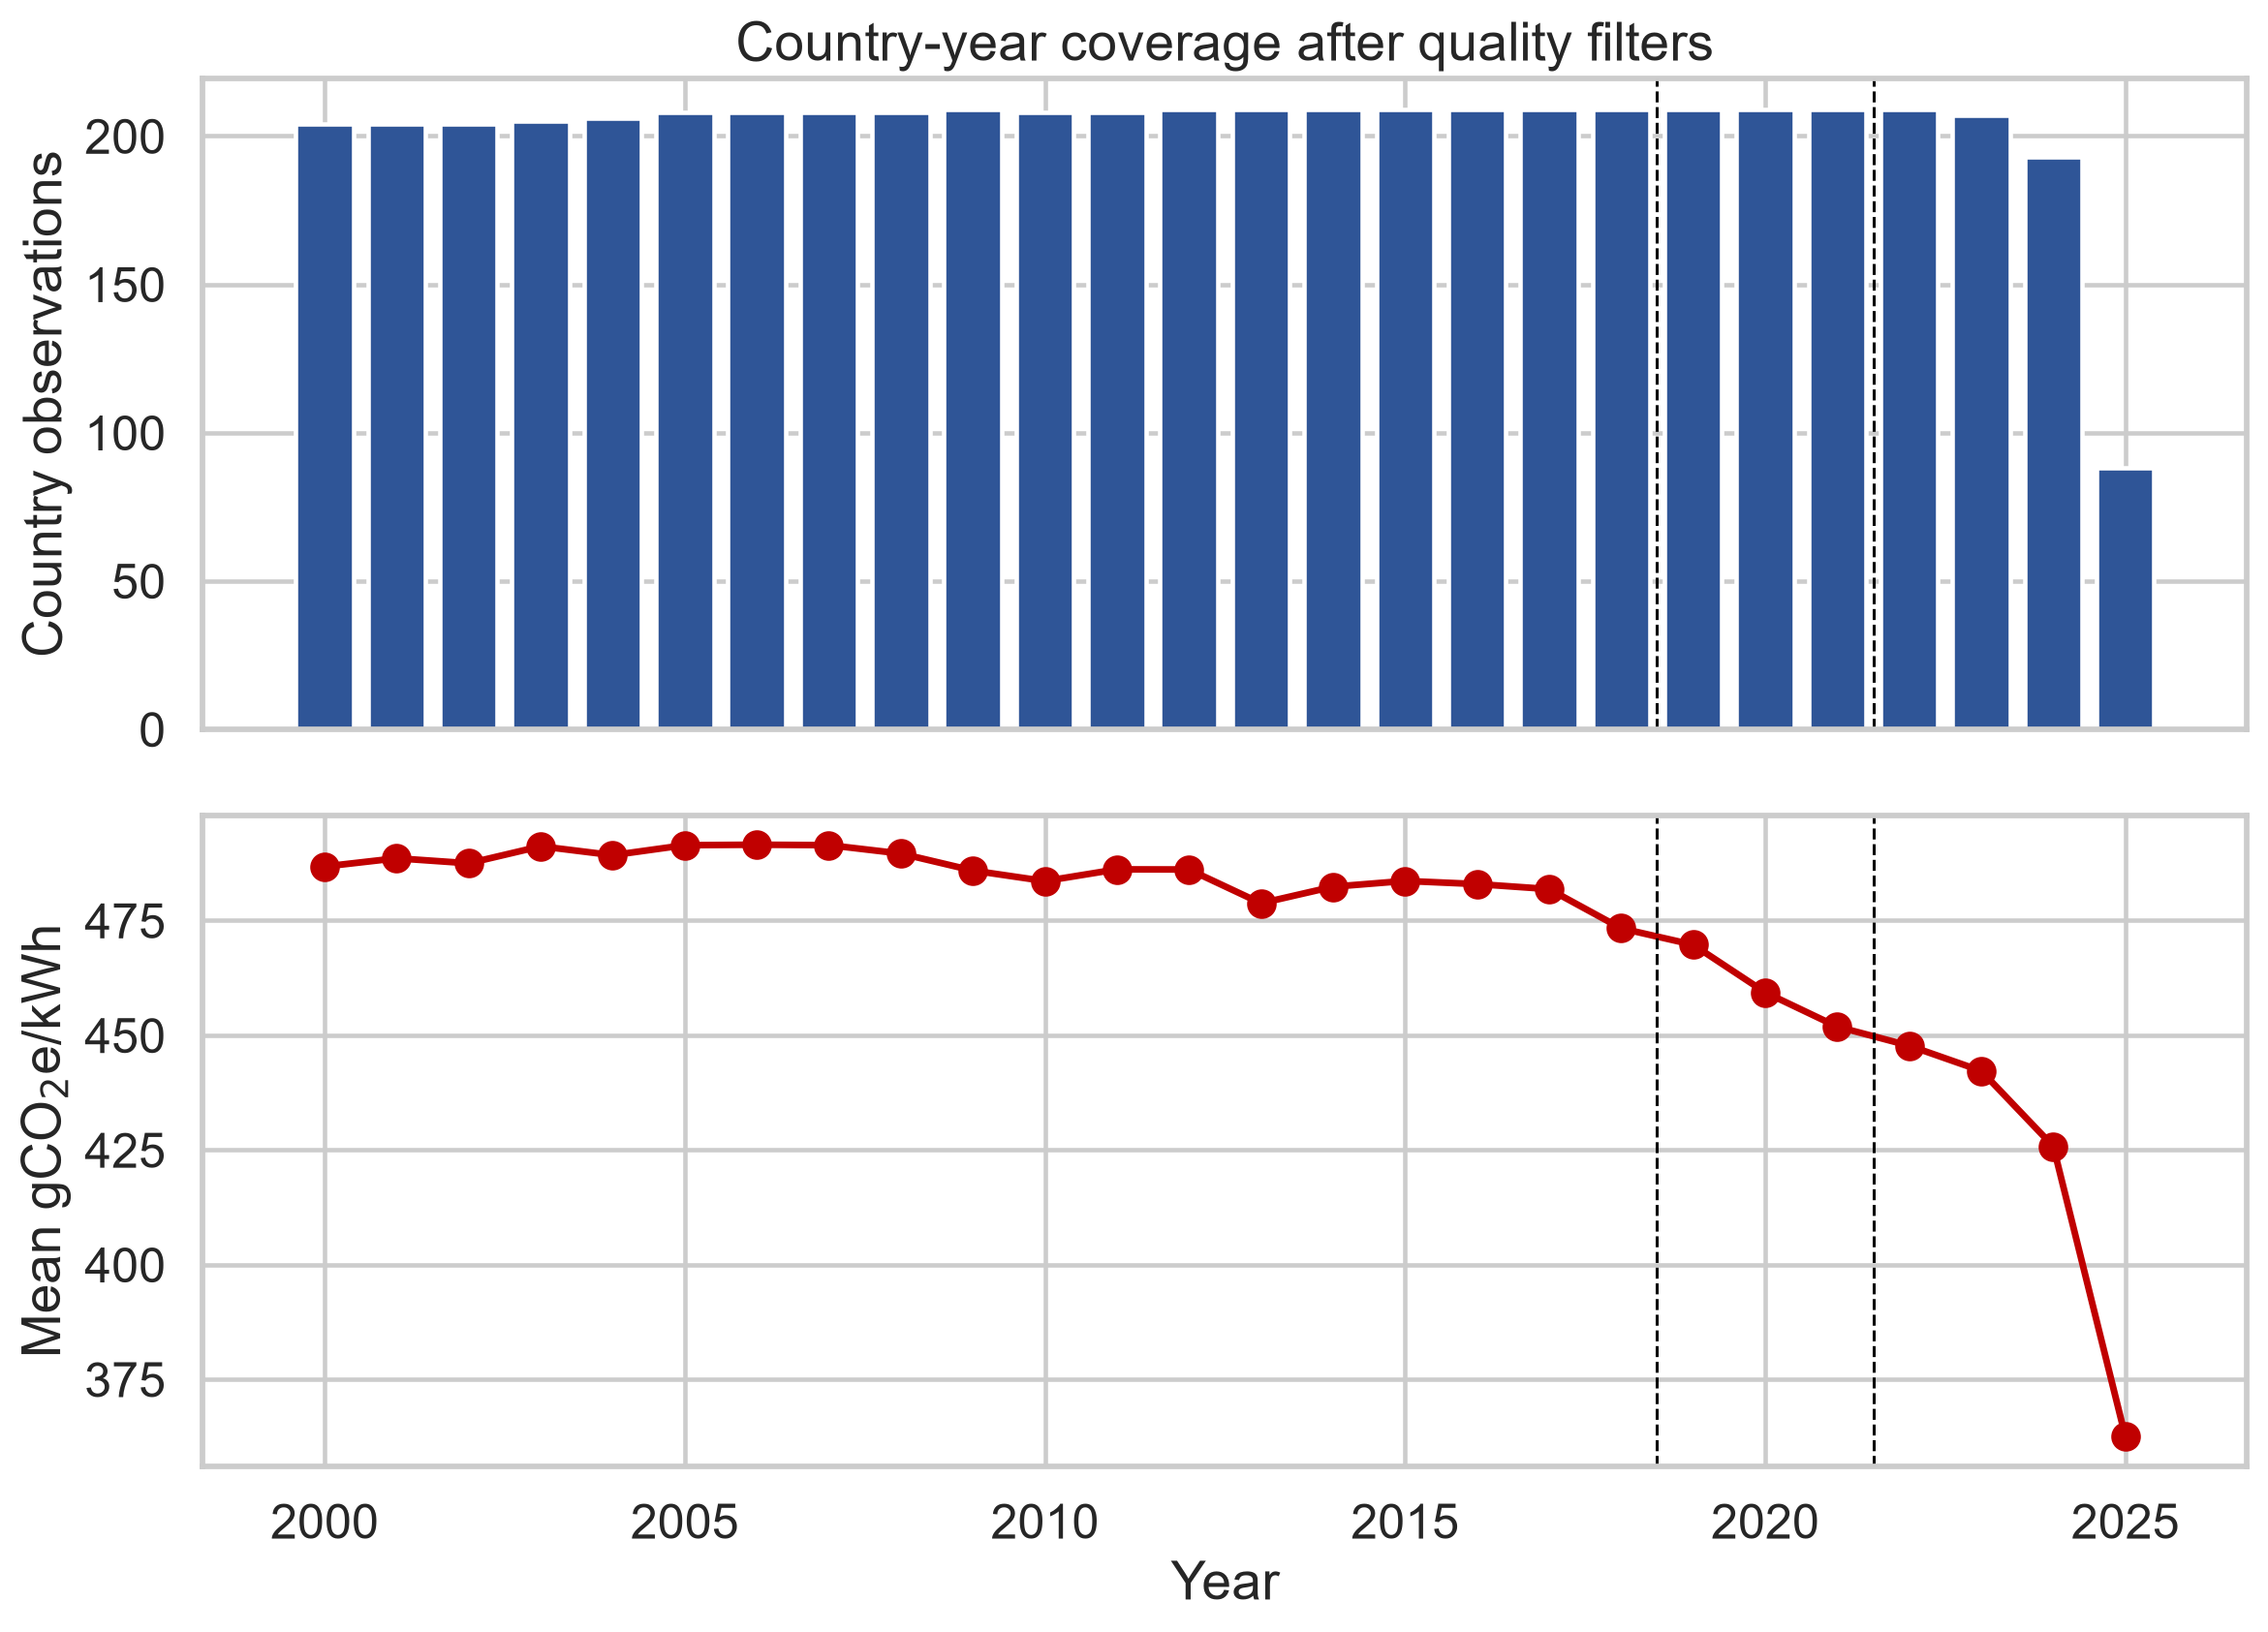

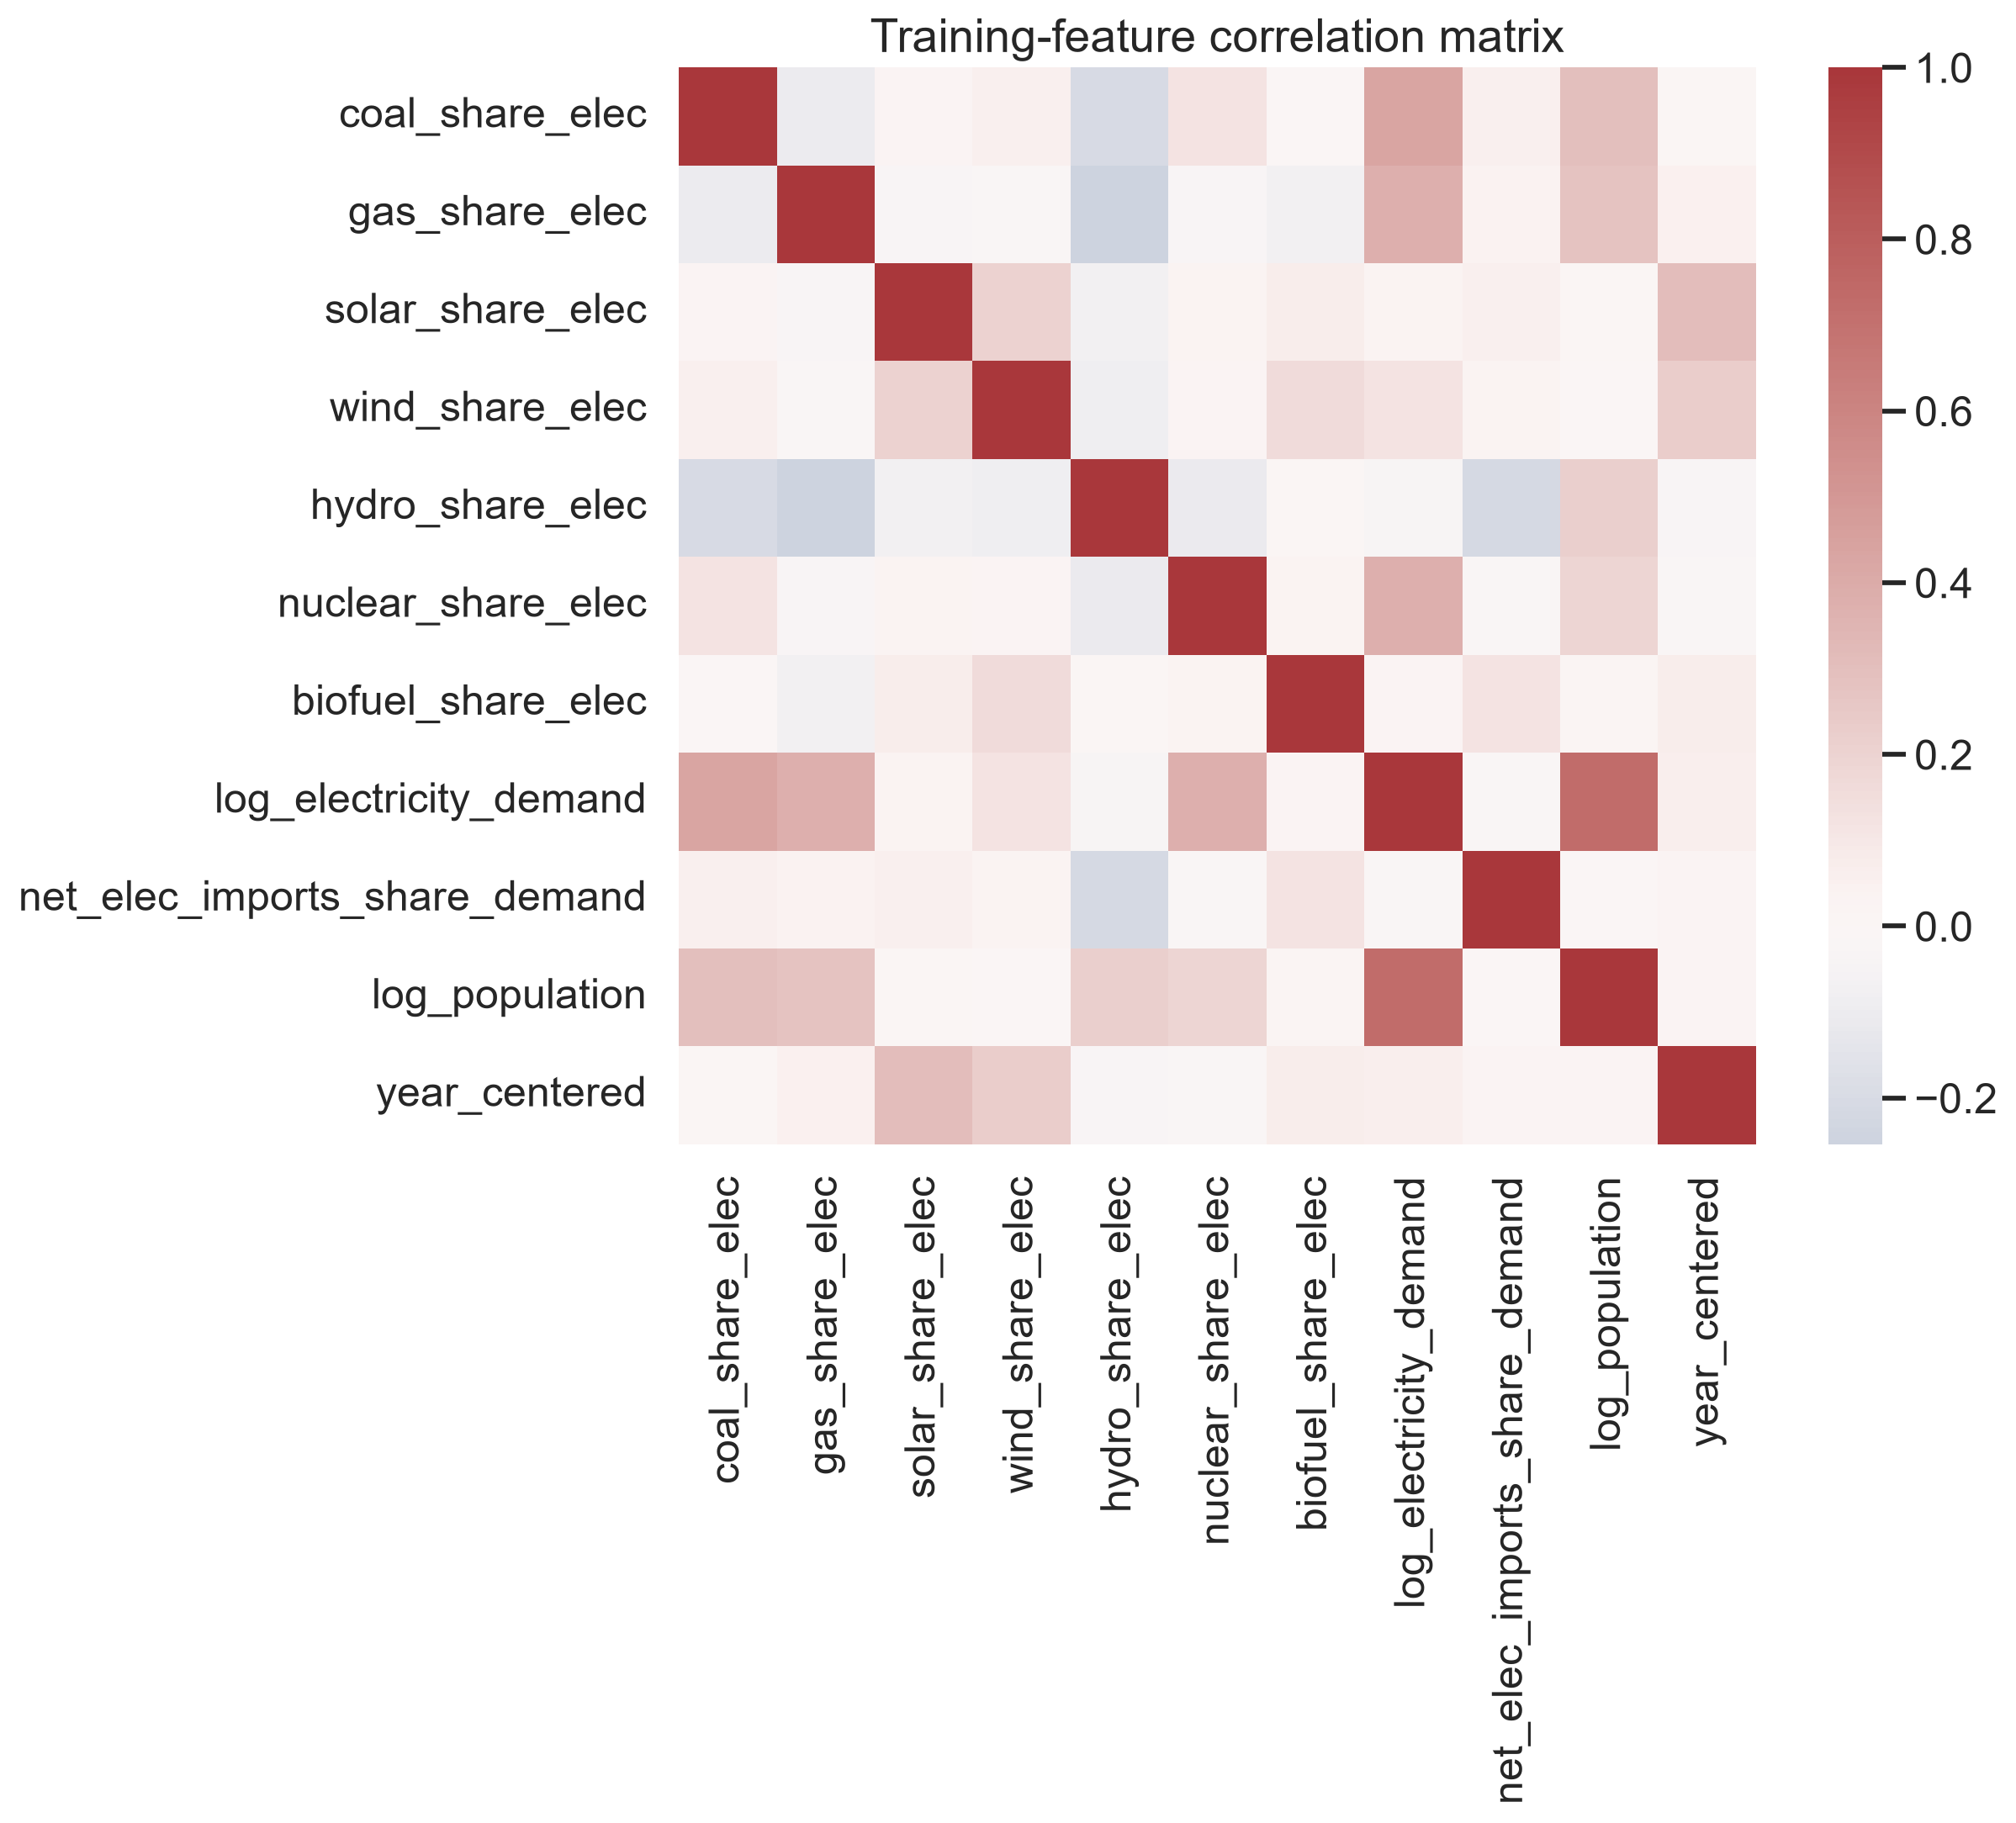

In [4]:
audit = json.loads((TABLE_DIR / 'data_audit.json').read_text(encoding='utf-8'))
missing = pd.read_csv(TABLE_DIR / 'panel_missingness.csv')
vif = pd.read_csv(TABLE_DIR / 'vif_train.csv')
display(pd.Series(audit, name='value').to_frame())
display(missing.sort_values('missing_percent', ascending=False).head(12))
display(vif)
display(Image(filename=str(FIGURE_DIR / 'panel_coverage_trend.png')))
display(Image(filename=str(FIGURE_DIR / 'feature_correlation_heatmap.png')))

## 5. Kết quả ngoài mẫu theo ba giao thức

,protocol,split,model,model_label,n,selected_parameters,mae,rmse,r2
5,temporal,test,catboost,CatBoost,697,"{""depth"": 6, ""iterations"": 800, ""learning_rate...",24.675368,41.040688,0.972215
4,temporal,test,xgboost,XGBoost,697,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",27.716542,47.691157,0.962480
3,temporal,test,random_forest,Random Forest,697,"{""max_depth"": null, ""max_features"": 0.8, ""min_...",30.700923,49.052267,0.960308
2,temporal,test,elastic_net,Elastic Net,697,"{""alpha"": 0.001, ""l1_ratio"": 0.7}",49.725797,82.775483,0.886971
1,temporal,test,ridge,Ridge,697,"{""alpha"": 0.01}",49.745661,82.781053,0.886956
0,temporal,test,linear_regression,Linear Regression,697,{},49.745797,82.781091,0.886956
8,unseen_country,test,elastic_net,Elastic Net,1047,"{""alpha"": 0.01, ""l1_ratio"": 0.2}",60.266232,100.377005,0.792947
7,unseen_country,test,ridge,Ridge,1047,"{""alpha"": 10.0}",60.818170,100.525616,0.792333
6,unseen_country,test,linear_regression,Linear Regression,1047,{},61.057097,100.592998,0.792055
10,unseen_country,test,xgboost,XGBoost,1047,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",59.485253,107.067453,0.764425


,protocol,held_out_region,model,model_label,train_n,test_n,test_countries,mae,rmse,r2
5,region_transfer,Africa,catboost,CatBoost,3344,168,56,51.911906,72.802932,0.908808
2,region_transfer,Africa,elastic_net,Elastic Net,3344,168,56,50.521639,75.796026,0.901155
1,region_transfer,Africa,ridge,Ridge,3344,168,56,50.559419,75.813899,0.901109
0,region_transfer,Africa,linear_regression,Linear Regression,3344,168,56,50.559786,75.814072,0.901108
4,region_transfer,Africa,xgboost,XGBoost,3344,168,56,57.861623,78.752499,0.893294
3,region_transfer,Africa,random_forest,Random Forest,3344,168,56,60.967134,88.508448,0.865219
11,region_transfer,America,catboost,CatBoost,3563,147,46,28.973184,40.185240,0.971213
10,region_transfer,America,xgboost,XGBoost,3563,147,46,33.226736,48.704675,0.957713
9,region_transfer,America,random_forest,Random Forest,3563,147,46,32.191050,49.680094,0.956002
8,region_transfer,America,elastic_net,Elastic Net,3563,147,46,36.413515,67.037206,0.919888


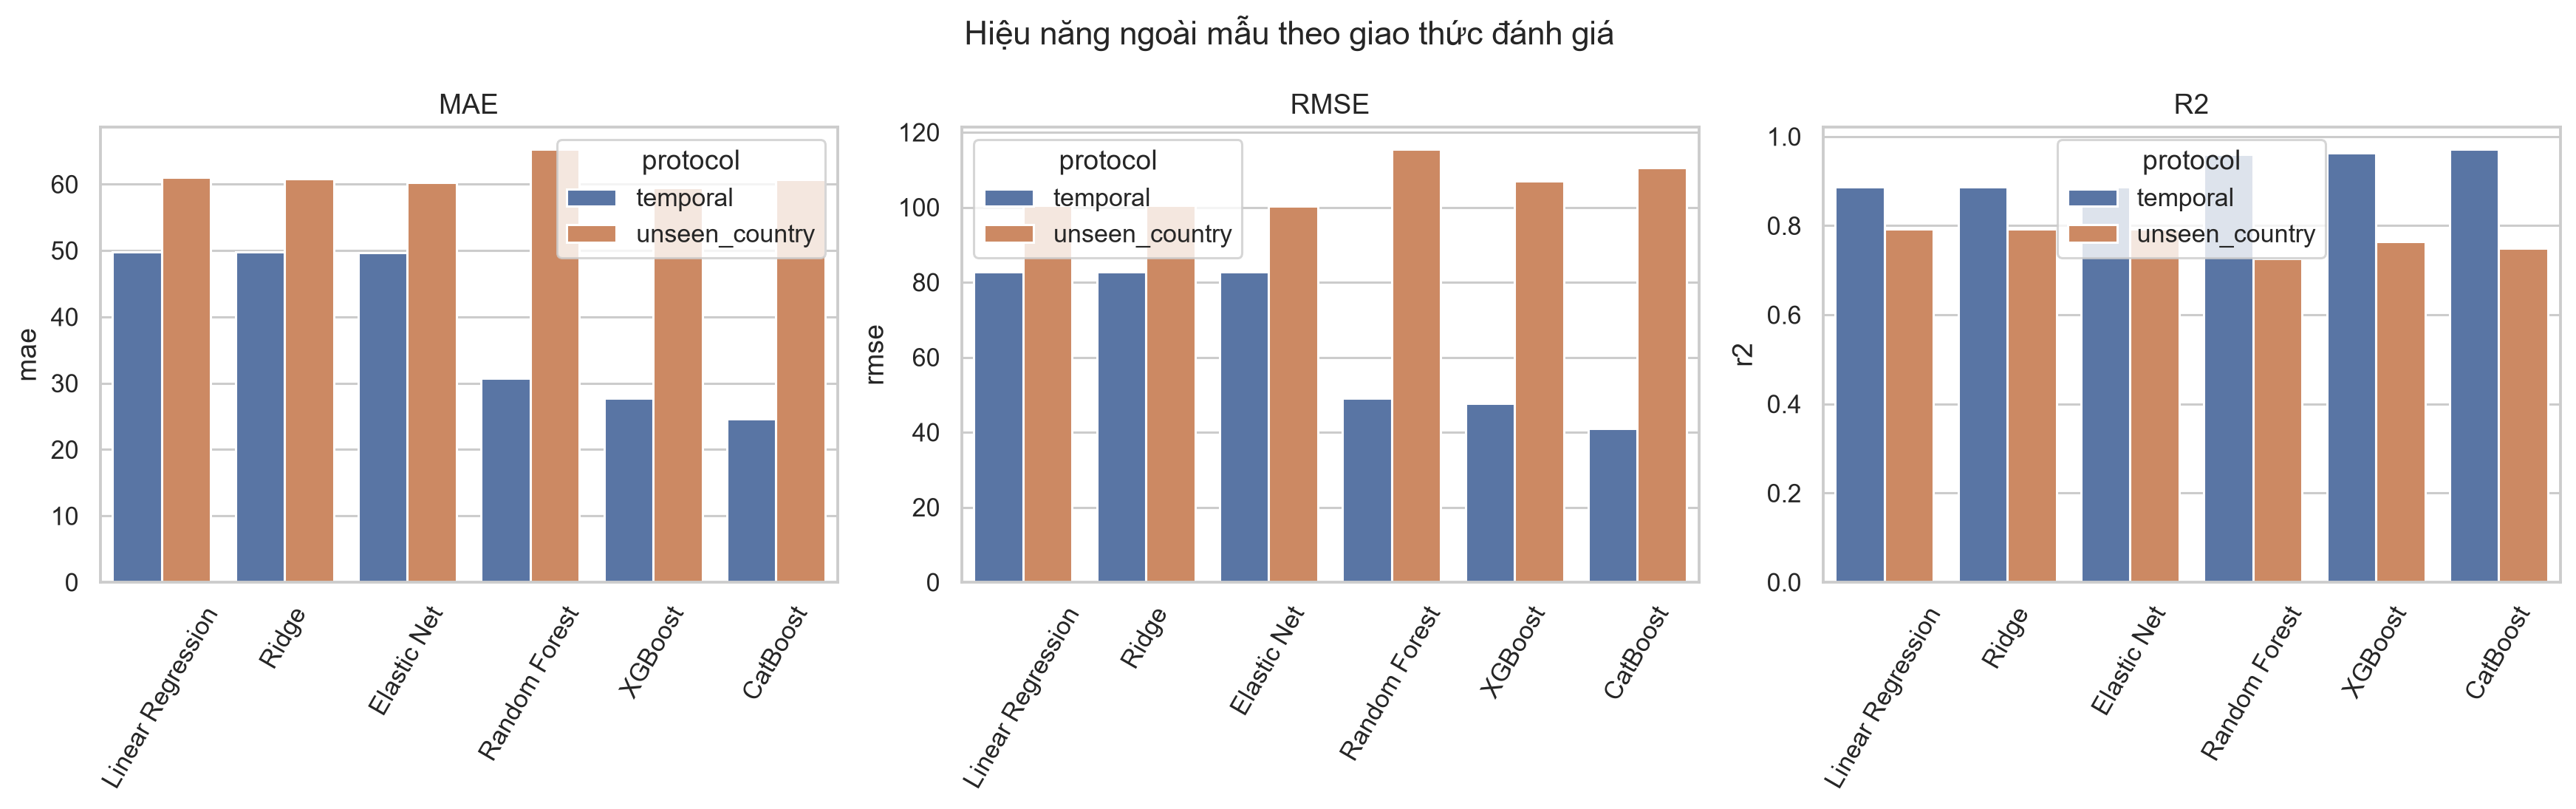

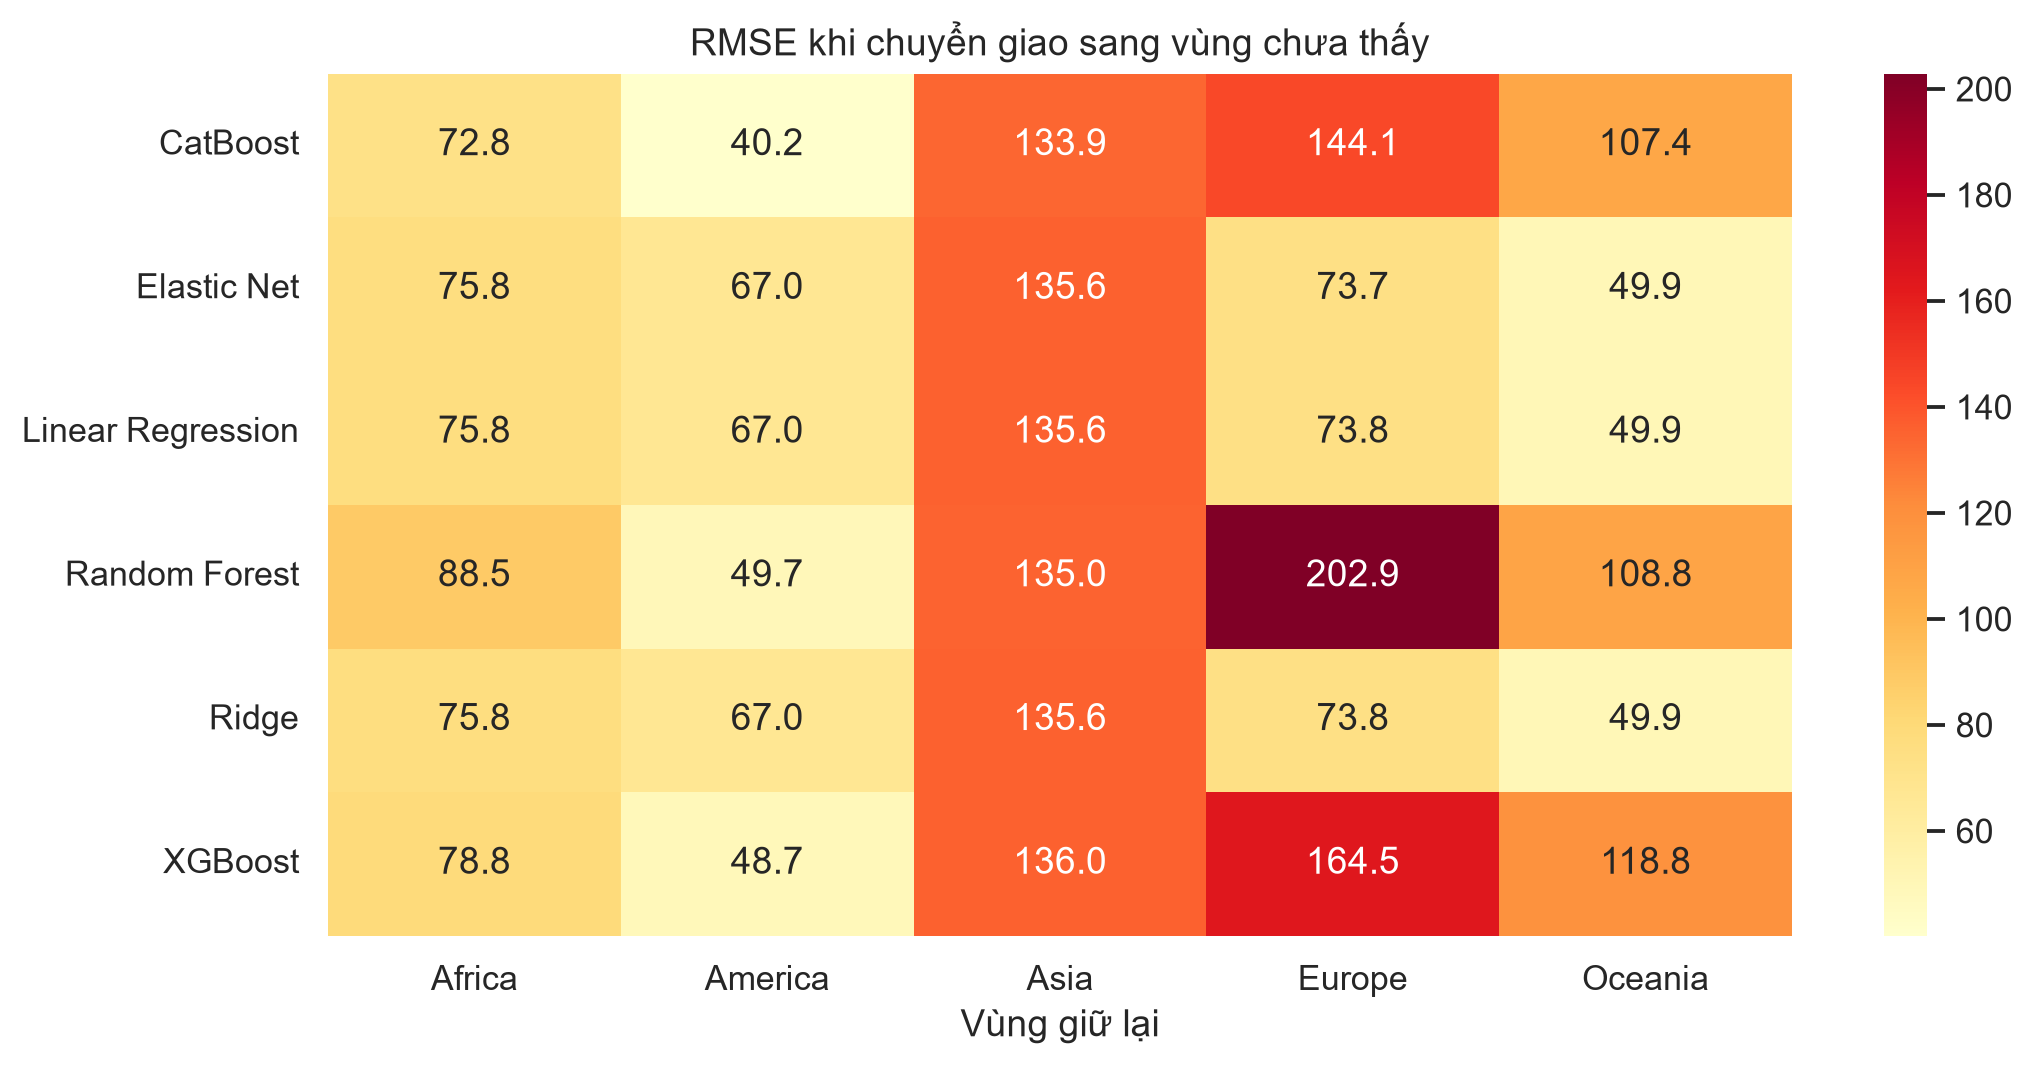

In [5]:
metrics = pd.read_csv(TABLE_DIR / 'model_metrics.csv')
region_transfer = pd.read_csv(TABLE_DIR / 'region_transfer_metrics.csv')
display(metrics.sort_values(['protocol', 'rmse']))
display(region_transfer.sort_values(['held_out_region', 'rmse']))
display(Image(filename=str(FIGURE_DIR / 'model_comparison.png')))
display(Image(filename=str(FIGURE_DIR / 'region_transfer_rmse.png')))

## 6. Explainable AI và heterogeneity

,feature,mean_abs_shap,mean_shap
0,hydro_share_elec,140.683400,9.728350
1,coal_share_elec,47.899995,-4.624916
2,wind_share_elec,34.633222,-21.441141
3,nuclear_share_elec,33.166926,-2.473455
4,biofuel_share_elec,25.634955,-8.448706
5,solar_share_elec,23.850015,-21.164149
6,gas_share_elec,14.742735,0.785692
7,log_electricity_demand,10.775275,-3.069727
8,net_elec_imports_share_demand,8.281356,-0.772921
9,log_population,7.406838,1.415841


,feature,importance_mean,importance_std
0,hydro_share_elec,207.771789,4.440094
1,coal_share_elec,69.181941,2.084344
2,nuclear_share_elec,60.429980,2.529835
3,wind_share_elec,52.526787,2.025217
4,biofuel_share_elec,32.440540,2.213768
5,gas_share_elec,31.693371,1.407460
6,solar_share_elec,26.030944,1.518231
7,log_electricity_demand,24.637519,1.371545
8,net_elec_imports_share_demand,18.692500,2.978195
9,log_population,12.377122,1.103720


,dimension,group,n,mae,rmse,r2
0,region,Africa,168,24.468076,40.087737,0.972351
1,region,America,147,15.597605,20.107650,0.992792
2,region,Asia,176,32.003835,55.768172,0.947757
3,region,Europe,160,24.650939,34.417781,0.974012
4,region,Oceania,46,26.487421,48.377918,0.919098
5,dominant_source,Coal,88,26.289678,36.041316,0.925274
6,dominant_source,Gas,189,36.475790,57.727024,0.915593
7,dominant_source,Hydro,181,15.546389,23.172112,0.956015
8,dominant_source,Nuclear,31,17.761658,20.308590,0.965232
9,dominant_source,Oil,180,16.795368,29.274296,0.952609


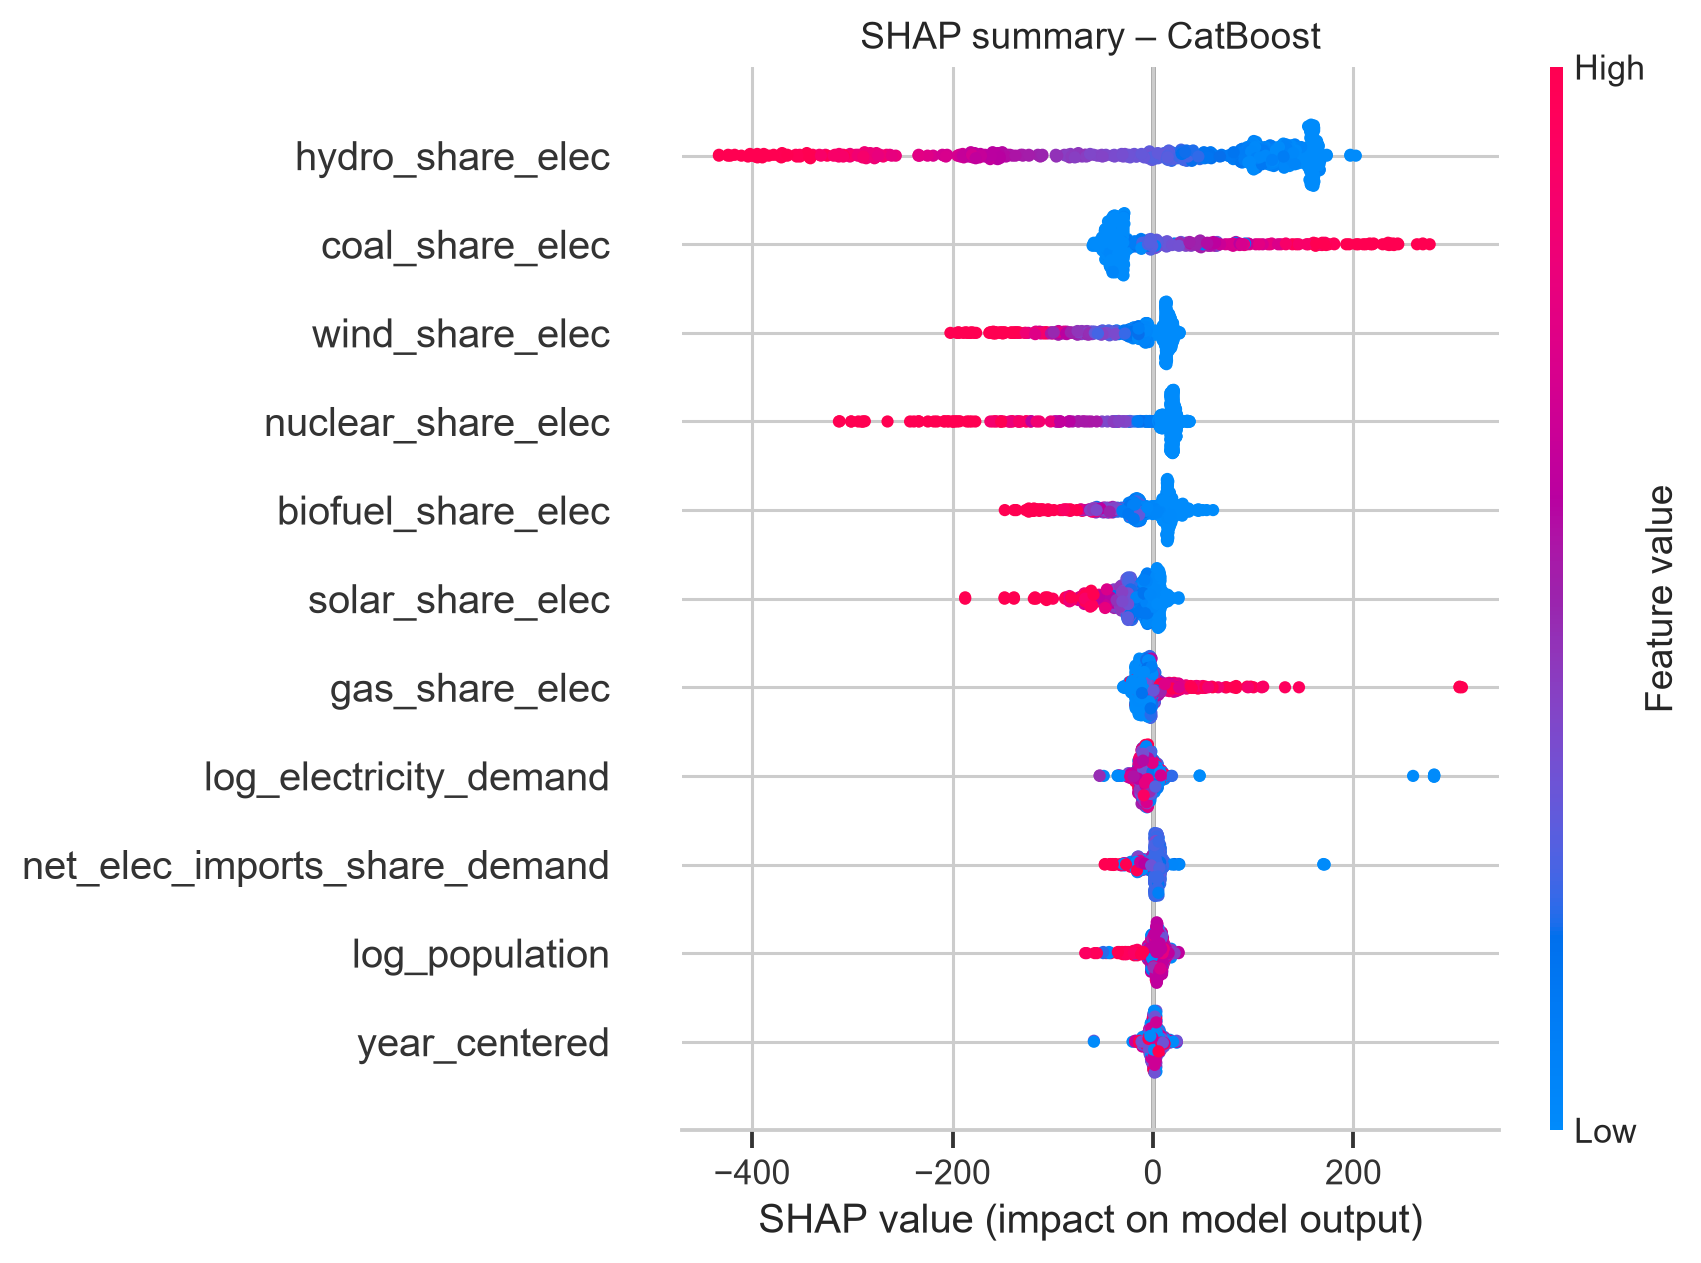

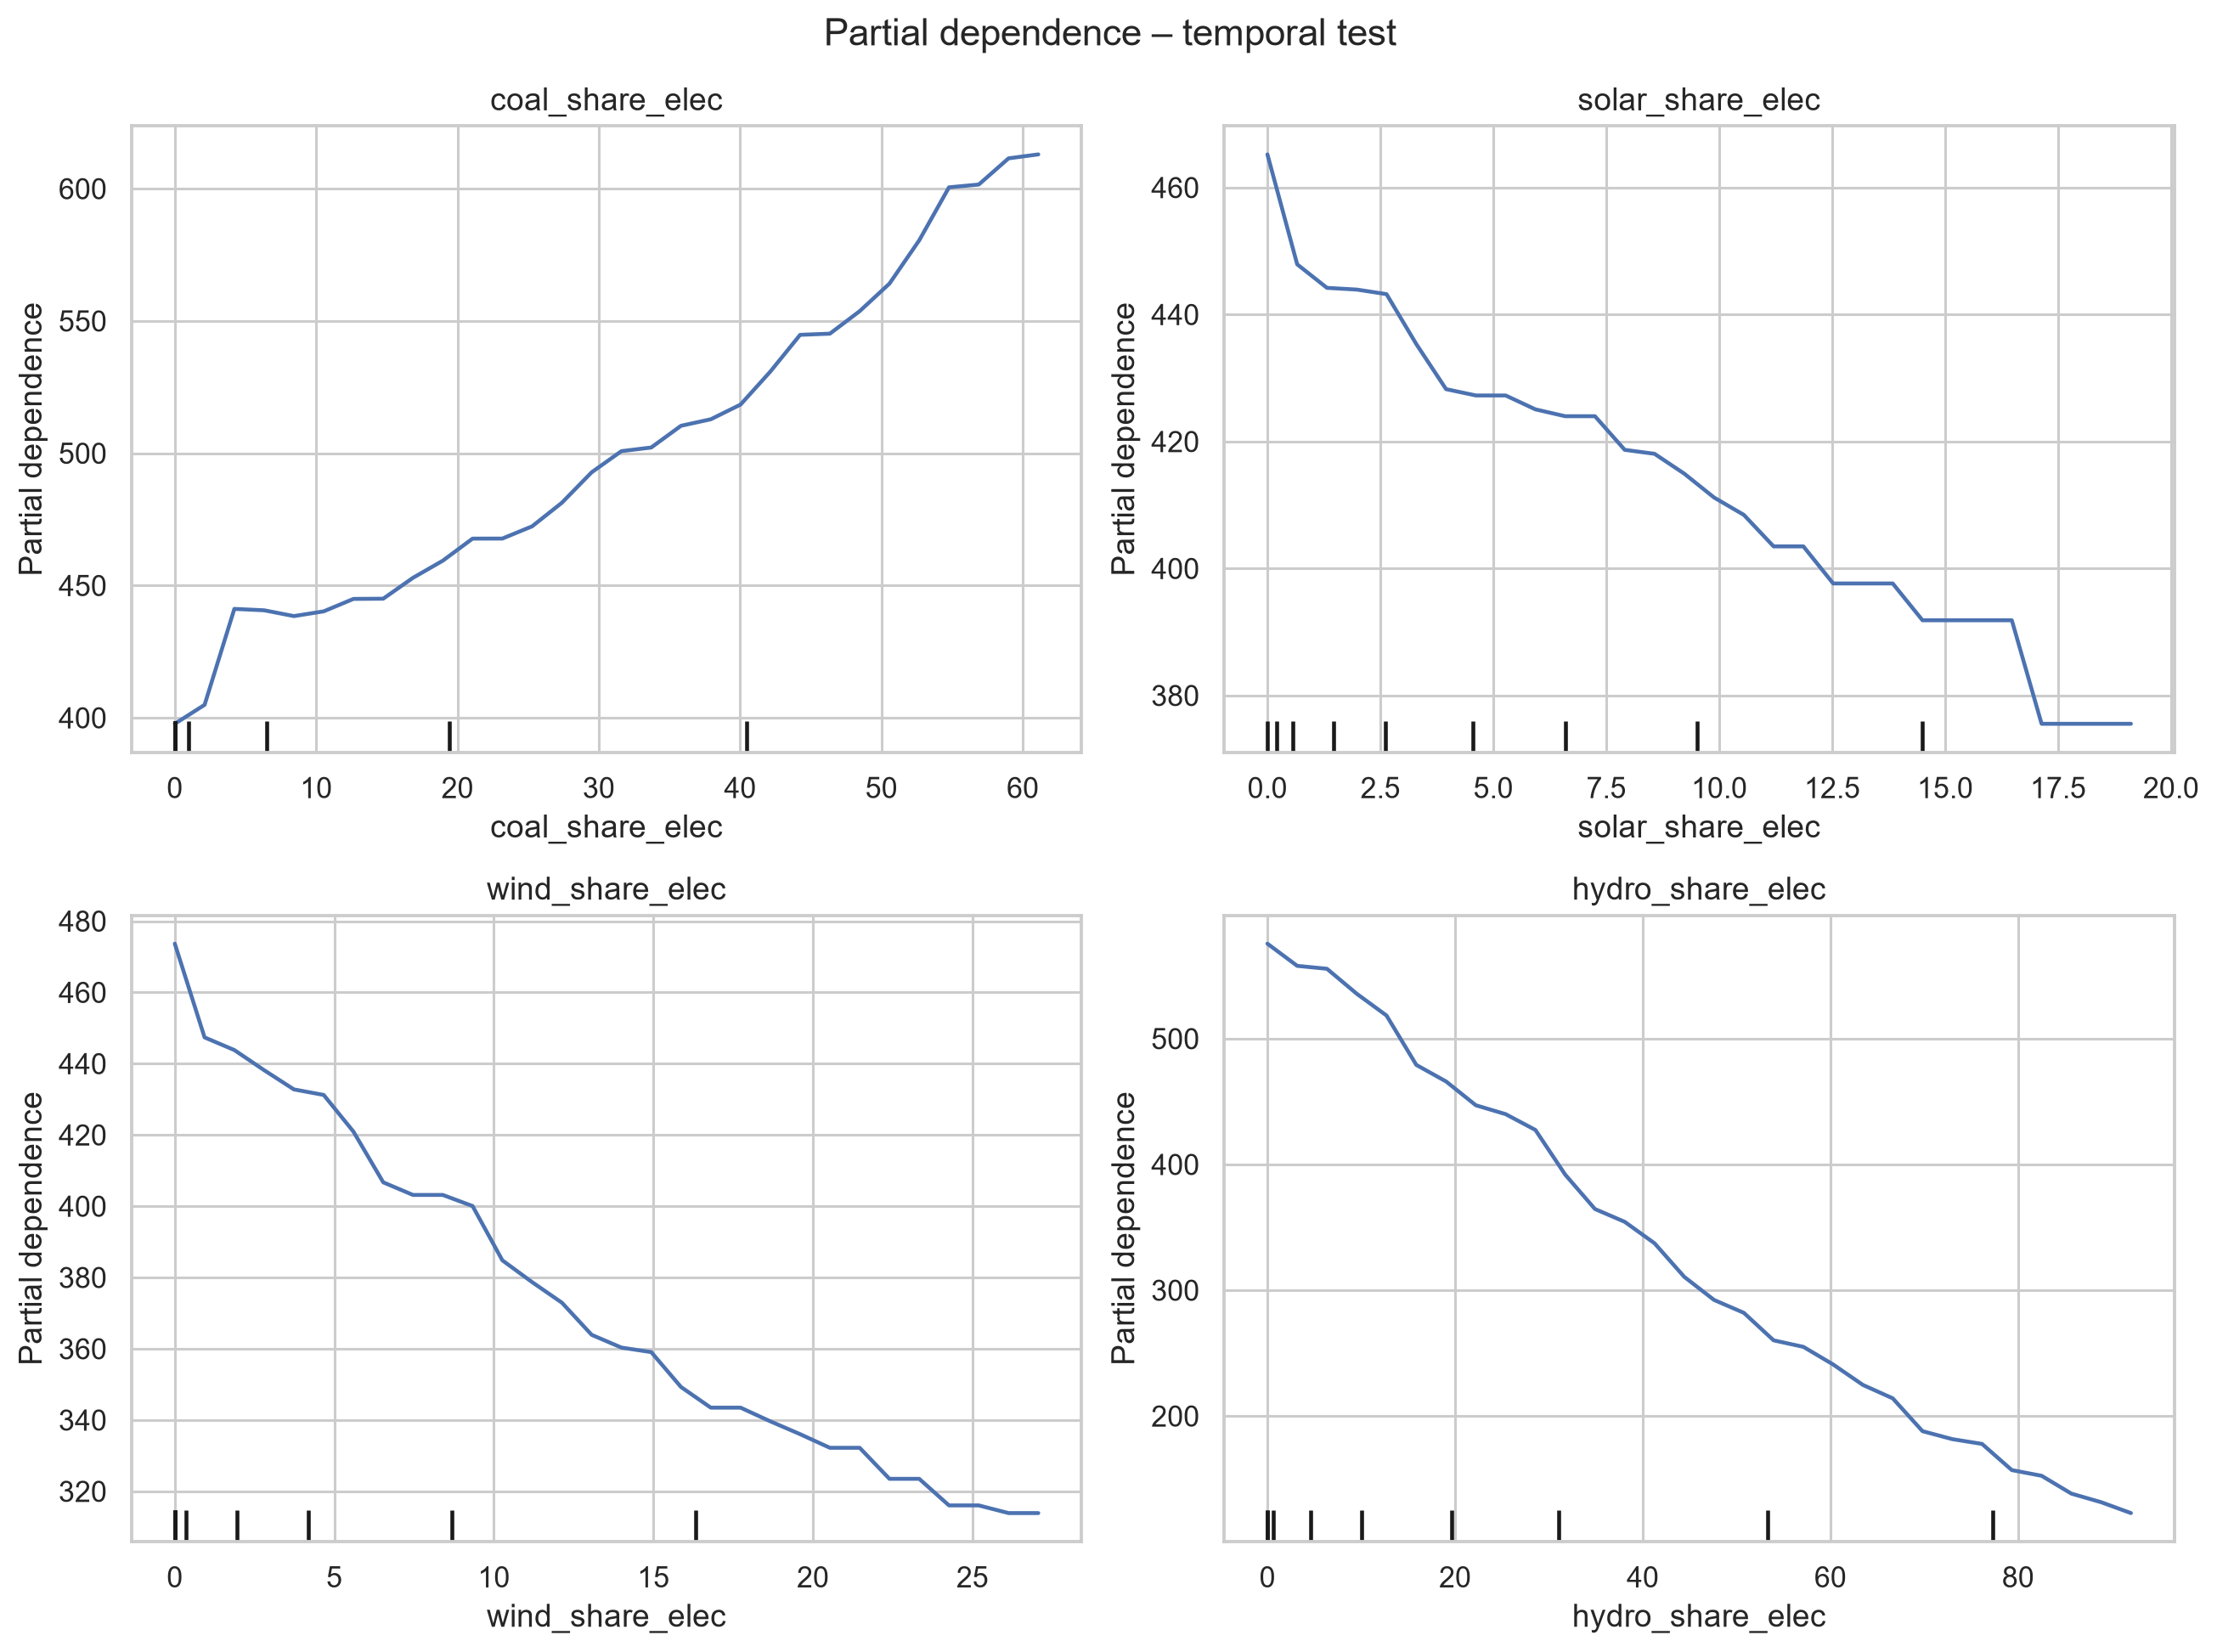

In [6]:
display(pd.read_csv(TABLE_DIR / 'shap_importance.csv').head(12))
display(pd.read_csv(TABLE_DIR / 'permutation_importance.csv').head(12))
display(pd.read_csv(TABLE_DIR / 'heterogeneity_metrics.csv'))
display(Image(filename=str(FIGURE_DIR / 'shap_summary.png')))
display(Image(filename=str(FIGURE_DIR / 'partial_dependence.png')))

## 7. Việt Nam và phân tích kịch bản
Các kịch bản là thay đổi phản thực *ceteris paribus* trong đầu vào mô hình, không phải ước lượng tác động nhân quả hay dự báo chính sách.

,year,carbon_intensity_gco2e_kwh,prediction,error
0,2022,415.41,431.711150,16.301150
1,2023,472.40,518.662931,46.262931
2,2024,484.32,572.558292,88.238292
3,2025,460.73,531.423635,70.693635


,scenario,country,iso_code,year,predicted_carbon_intensity,change_vs_model_baseline,change_percent,coal_share_elec,gas_share_elec,oil_share_elec,solar_share_elec,wind_share_elec,hydro_share_elec,nuclear_share_elec,biofuel_share_elec,other_renewables_share_elec
0,Quan sát cơ sở,Vietnam,VNM,2025,531.423635,0.000000,0.000000,48.143488,6.238911,0.200006,7.432498,4.635633,33.017194,0.0,0.332269,0.332269
1,"Solar +5, coal -5",Vietnam,VNM,2025,482.854061,-48.569575,-9.139521,43.143488,6.238911,0.200006,12.432498,4.635633,33.017194,0.0,0.332269,0.332269
2,"Wind +5, coal -5",Vietnam,VNM,2025,470.289681,-61.133954,-11.503808,43.143488,6.238911,0.200006,7.432498,9.635633,33.017194,0.0,0.332269,0.332269
3,"Solar +5, wind +5, coal -10",Vietnam,VNM,2025,427.479626,-103.944009,-19.559538,38.143488,6.238911,0.200006,12.432498,9.635633,33.017194,0.0,0.332269,0.332269
4,"Nuclear +5, coal -5",Vietnam,VNM,2025,470.565079,-60.858556,-11.451985,43.143488,6.238911,0.200006,7.432498,4.635633,33.017194,5.0,0.332269,0.332269
5,"Hydro -5, gas +5",Vietnam,VNM,2025,573.884842,42.461207,7.990086,48.143488,11.238911,0.200006,7.432498,4.635633,28.017194,0.0,0.332269,0.332269


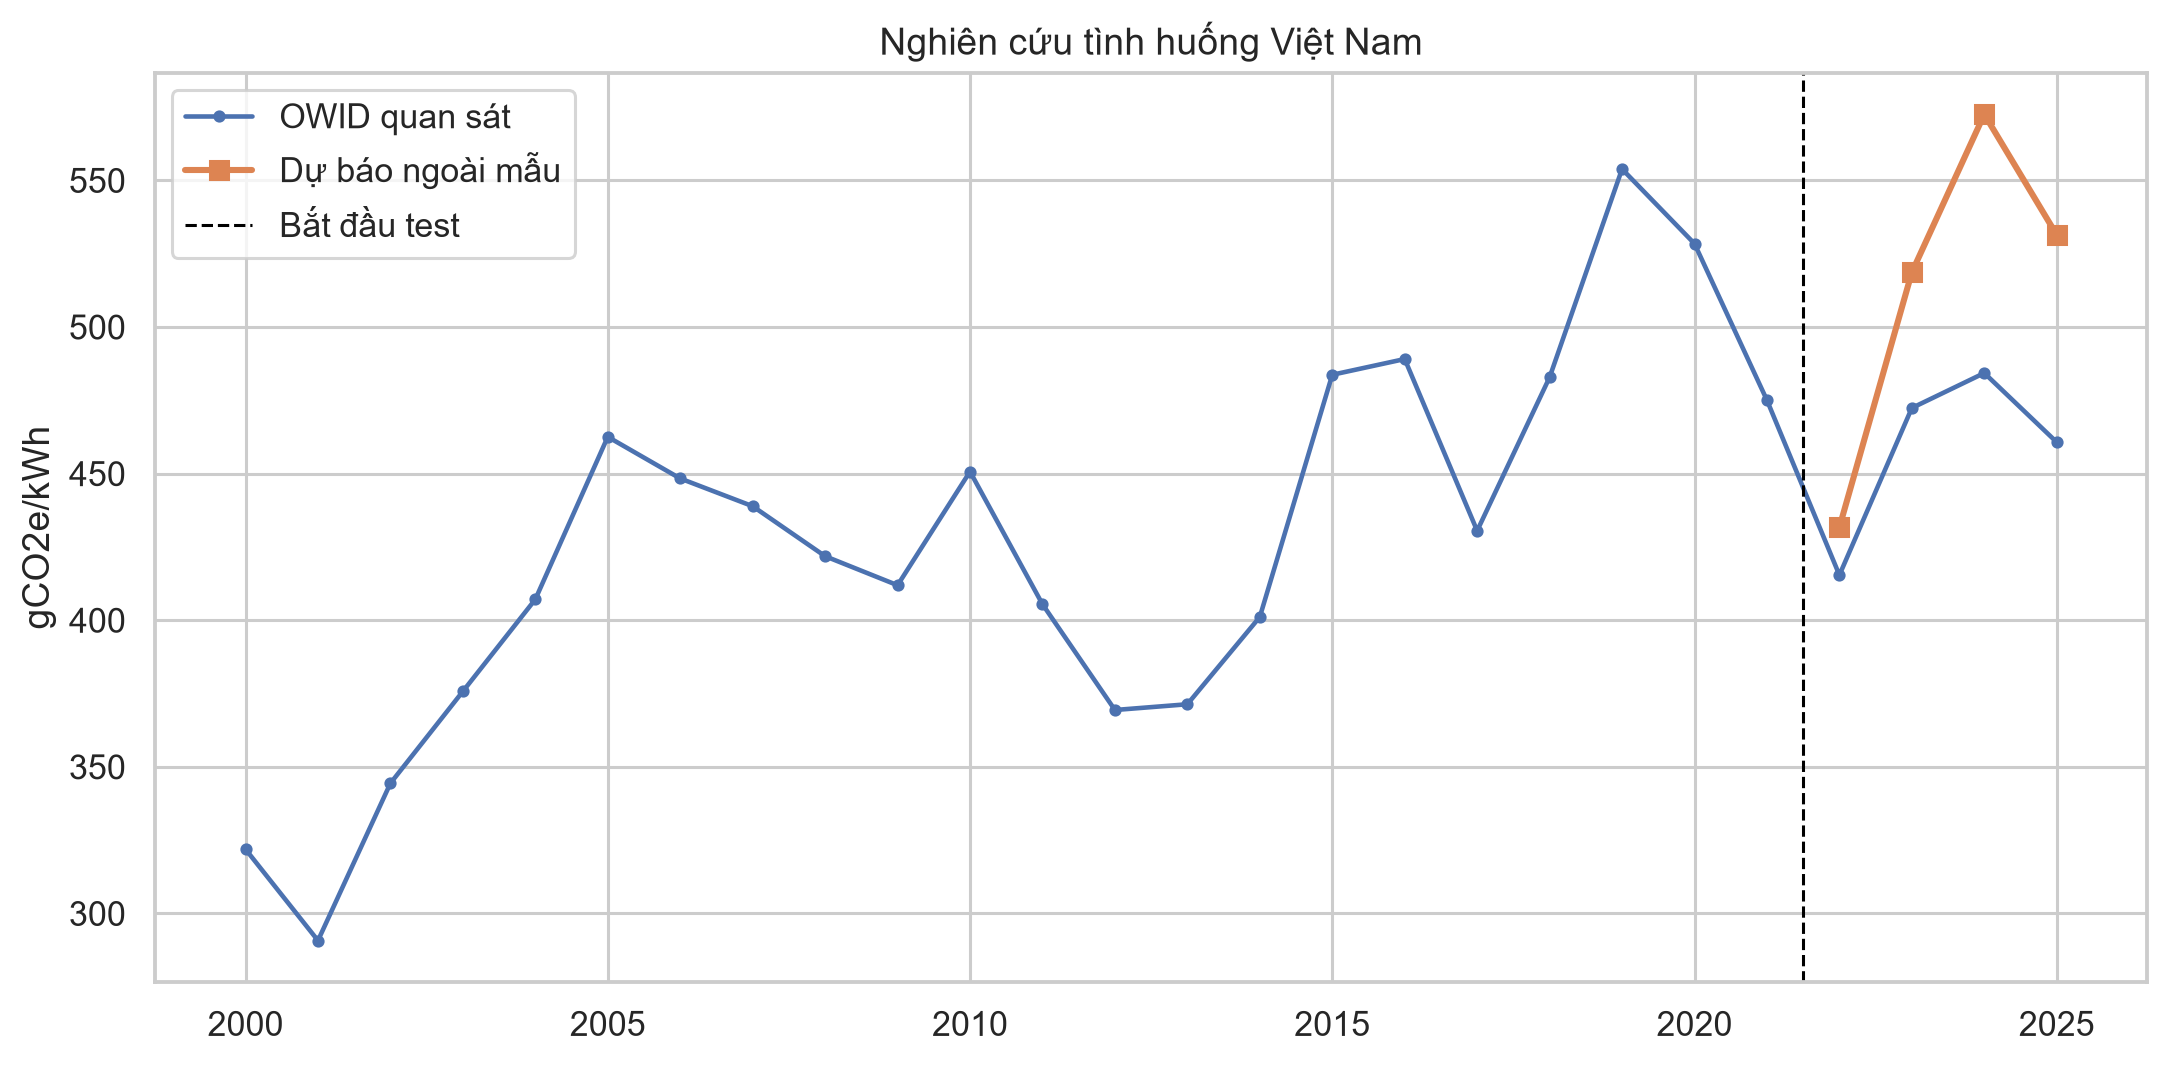

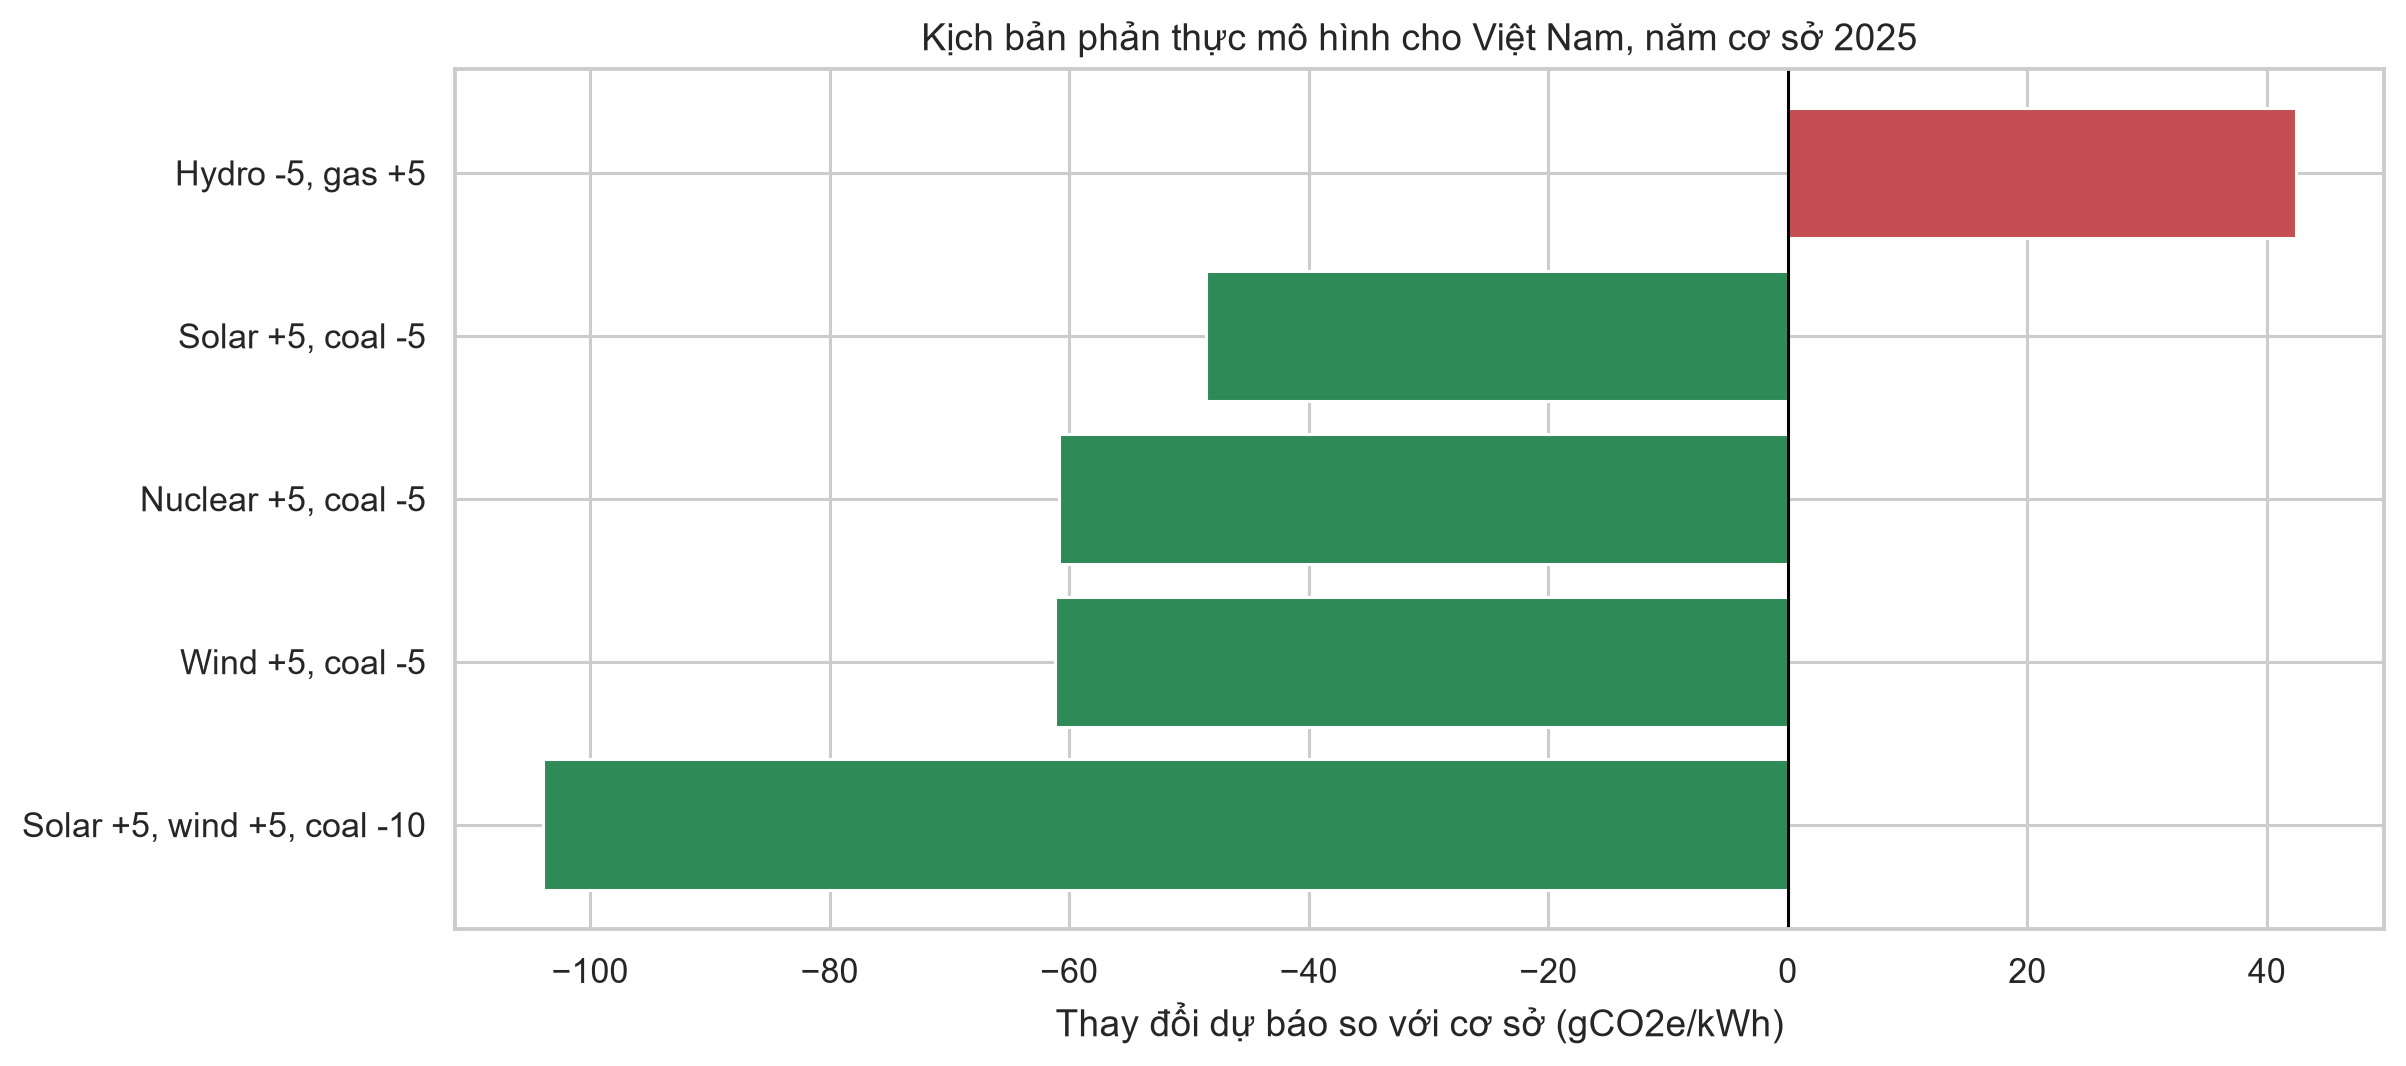

In [7]:
display(pd.read_csv(TABLE_DIR / 'vietnam_temporal_case.csv')[['year','carbon_intensity_gco2e_kwh','prediction','error']])
display(pd.read_csv(TABLE_DIR / 'vietnam_scenarios.csv'))
display(Image(filename=str(FIGURE_DIR / 'vietnam_case.png')))
display(Image(filename=str(FIGURE_DIR / 'vietnam_scenarios.png')))

## 8. Khả năng tái lập
Manifest lưu phiên bản môi trường, seed, URL nguồn và SHA-256 của snapshot dữ liệu.

In [8]:
manifest = json.loads((ROOT / 'outputs' / 'thesis' / 'run_manifest.json').read_text(encoding='utf-8'))
manifest

{'generated_at_utc': '2026-10-04T12:42:59.215651+00:00',
 'python': '3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]',
 'platform': 'Windows-11-10.0.26200-SP0',
 'packages': {'pandas': '2.3.3',
  'numpy': '2.5.3',
  'scikit_learn': '1.9.1',
  'xgboost': '3.4.1',
  'shap': '0.52.0'},
 'random_seed': 42,
 'source_urls': {'electricity_by_source': 'https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=by_source&frequency=annual',
  'electricity_generation': 'https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=generation&frequency=annual',
  'electricity_demand': 'https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=total&metric=demand&frequency=annual',
  'net_imports': 'https://ourworldindata.org/grapher/electricity-mix.csv?v=1&csvType=full&useColumnShortNames=false&source=to